# Práctica demostrativa — Manipular bandas para responder preguntas

En la clase 2 elegimos imágenes según lo que necesitábamos observar. Ahora trabajaremos con una escena **real** de Sentinel‑2B, del 12/08/2024, en la costa de Países Bajos. La práctica avanza por tres operaciones: **1) cambiar la combinación de bandas, 2) calcular NDVI y NDWI para cada píxel, 3) seleccionar zonas candidatas con umbrales**.

Cada ejercicio modifica o transforma una imagen y muestra el resultado. En parejas, prueben los cambios indicados y describan qué cambió y qué todavía no se puede concluir. Las celdas de visualización ya tienen resultados guardados para que la demostración pueda verse sin descargar datos.

## Siglas para leer el notebook

- **NDVI** (*Normalized Difference Vegetation Index*): Índice de Vegetación de Diferencia Normalizada. En esta práctica compara rojo y **NIR**.
- **NDWI** (*Normalized Difference Water Index*): Índice de Agua de Diferencia Normalizada. Hay varias fórmulas con este nombre; acá usamos verde–NIR para agua abierta.
- **NIR** (*Near Infrared*): infrarrojo cercano.
- **SWIR** (*Short-Wave Infrared*): infrarrojo de onda corta. La variante NIR–SWIR se relaciona con agua en la vegetación y suele llamarse **NDMI** (*Normalized Difference Moisture Index*, Índice de Diferencia Normalizada de Humedad).
- **RGB** (*Red, Green, Blue*): rojo, verde y azul, los tres canales de una visualización a color.

En Sentinel‑2, **B02** es azul, **B03** verde, **B04** rojo y **B08** NIR. Son códigos de bandas. La escena preparada no contiene SWIR, por eso en este notebook calculamos NDWI verde–NIR, pero no la variante NIR–SWIR. [USGS: siglas de sensores y bandas](https://www.usgs.gov/landsat-missions/landsat-acronyms); [USGS: nombres del índice NIR–SWIR](https://www.usgs.gov/publications/terminology-spectral-vegetation-index-nir-swirnir-swir).

En la ficha de preparación, **DN** (*Digital Number*) es el valor digital original y **SCL** (*Scene Classification Layer*) es la capa de clasificación que se usa para revisar calidad. No son índices.

## La imagen de trabajo

El archivo local contiene cuatro bandas de reflectancia de superficie, ya alineadas en una grilla común de 10 m: azul B02, verde B03, rojo B04 e infrarrojo cercano B08 (**NIR**). Cada banda es una medición distinta de la misma superficie. Un píxel cubre 10 m × 10 m y puede mezclar, por ejemplo, agua con arena o vegetación con suelo.

El RGB combina rojo, verde y azul para que reconozcamos el lugar. Sus valores se ajustaron para mostrarse en pantalla; **no usaremos esos colores ajustados para calcular índices**. Las cuentas se hacen con las bandas de reflectancia del archivo preparado, descrito en la [ficha de fuente y preparación](../../assets/geospatial/costa_paises_bajos_s2_20240812_fuente.md).

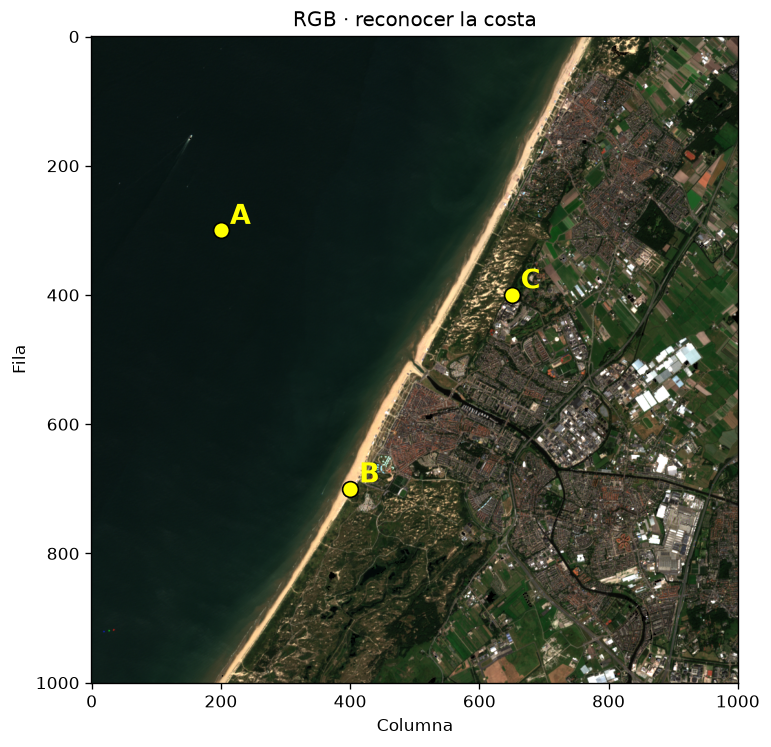

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio

ruta = Path('../../assets/geospatial/costa_paises_bajos_s2_20240812_reflectancia.tif')
if not ruta.exists():
    ruta = Path('assets/geospatial/costa_paises_bajos_s2_20240812_reflectancia.tif')
with rasterio.open(ruta) as escena:
    azul, verde, rojo, nir = escena.read()

rgb = np.clip(np.nan_to_num(np.dstack((rojo, verde, azul))) / 0.30, 0, 1)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(rgb)
for letra, fila, columna in [('A', 300, 200), ('B', 700, 400), ('C', 400, 650)]:
    ax.scatter(columna, fila, s=90, c='yellow', edgecolors='black')
    ax.text(columna + 14, fila - 10, letra, color='yellow', weight='bold', fontsize=16)
ax.set(title='RGB · reconocer la costa', xlabel='Columna', ylabel='Fila')
plt.show()

## Ejercicio 1 · Cambiá la combinación de bandas (12 minutos)

En la imagen RGB, la pantalla muestra **rojo, verde y azul**. También podemos asignar otras bandas a esos tres canales de pantalla: es una visualización en **falso color**. Acá vamos a poner NIR en el canal rojo de pantalla, rojo en el verde y verde en el azul.

Ejecutá la celda siguiente y compará las dos vistas. Después, cambiá el orden de `np.dstack((nir, rojo, verde))` por `np.dstack((rojo, nir, verde))` y volvé a ejecutarla.

- ¿Qué zonas cambian más de color entre una combinación y otra?
- ¿Qué aporta mostrar NIR en el canal rojo de pantalla?
- ¿Cambió la medición del archivo, o solo la forma de mostrarla?

La composición falsa sirve para hacer visibles diferencias espectrales; sus colores **no son colores naturales ni etiquetas de cultivos**.

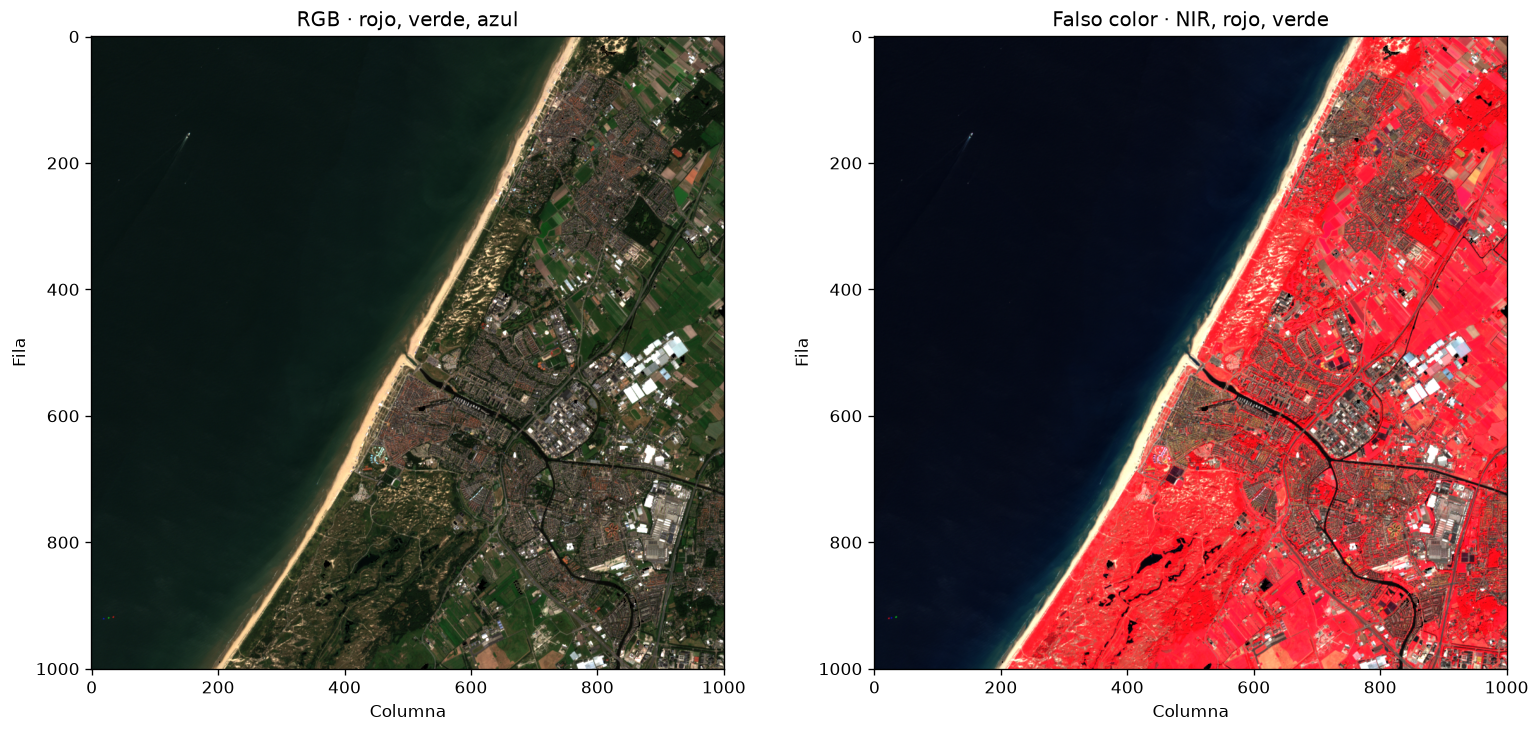

In [2]:
falso_color = np.clip(np.nan_to_num(np.dstack((nir, rojo, verde))) / 0.30, 0, 1)
fig, ejes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
ejes[0].imshow(rgb)
ejes[0].set_title('RGB · rojo, verde, azul')
ejes[1].imshow(falso_color)
ejes[1].set_title('Falso color · NIR, rojo, verde')
for ax in ejes:
    ax.set_xlabel('Columna')
    ax.set_ylabel('Fila')
plt.show()

### Qué hacemos al calcular un índice

La vegetación suele **absorber más rojo y reflejar más NIR**. NDVI resume ese contraste:

**NDVI = (NIR − rojo) / (NIR + rojo)**

La resta indica cuál banda es mayor. La suma pone esa diferencia en relación con la magnitud de las dos mediciones: una resta de 0,03 es grande si las bandas rondan 0,02, pero pequeña si rondan 0,30. Si las bandas son parecidas, el índice queda cerca de cero. Con reflectancias no negativas, los valores van de −1 a +1. El signo por sí solo no nombra una superficie.

Para explorar **agua abierta**, usamos NDWI de verde y NIR:

**NDWI de agua abierta = (verde − NIR) / (verde + NIR)**

El agua abierta suele reflejar poco NIR, así que el mar puede destacarse con valores positivos. «NDWI» también puede referirse a una fórmula NIR–SWIR para estudiar agua en la vegetación; esa variante requiere una banda SWIR que este archivo no tiene. Siempre pedí la fórmula y las bandas.

Los índices se calculan **píxel por píxel** usando bandas correspondientes al mismo lugar. Un mapa transforma el conjunto de resultados en una imagen que ayuda a comparar patrones. No indica especie ni diagnóstico de riego. El NDVI además puede verse afectado por el suelo entre plantas y perder sensibilidad en vegetación muy densa. [USGS: interpretación y límites del NDVI](https://www.usgs.gov/special-topics/remote-sensing-phenology/science/ndvi-foundation-remote-sensing-phenology).

## Ejercicio 2 · Calculá índices y compará sus mapas (18 minutos)

Ejecutá el cálculo. Seguí una fila de la celda: identificá qué bandas se restan y se suman para NDVI y cuáles para NDWI. Los mapas usan la misma escala visual de −1 a +1, pero responden preguntas diferentes.

Luego compará A (mar), B (playa) y C (zona verde) en los mapas y en el RGB. Los valores de ejemplo impresos abajo corresponden solo a esos píxeles de esta fecha.

A: NDVI -0.37 · NDWI agua abierta 0.63
B: NDVI 0.05 · NDWI agua abierta -0.14
C: NDVI 0.93 · NDWI agua abierta -0.88


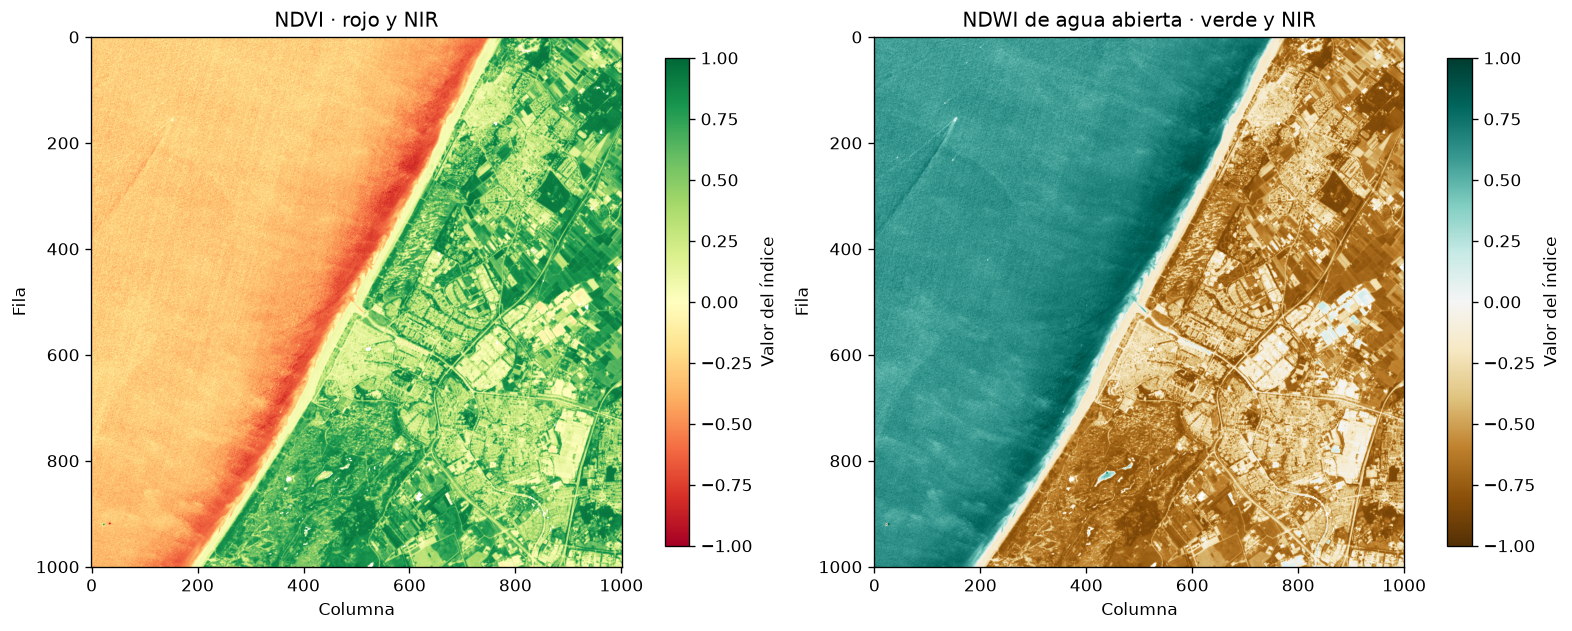

In [3]:
ndvi = (nir - rojo) / (nir + rojo)
ndwi_agua = (verde - nir) / (verde + nir)

fig, ejes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, mapa, titulo, colores in [
    (ejes[0], ndvi, 'NDVI · rojo y NIR', 'RdYlGn'),
    (ejes[1], ndwi_agua, 'NDWI de agua abierta · verde y NIR', 'BrBG')
]:
    vista = ax.imshow(mapa, cmap=colores, vmin=-1, vmax=1)
    ax.set(title=titulo, xlabel='Columna', ylabel='Fila')
    fig.colorbar(vista, ax=ax, fraction=0.046, pad=0.04, label='Valor del índice')
plt.show()

for letra, fila, columna in [('A', 300, 200), ('B', 700, 400), ('C', 400, 650)]:
    print(f'{letra}: NDVI {ndvi[fila, columna]:.2f} · NDWI agua abierta {ndwi_agua[fila, columna]:.2f}')

### Leé el resultado

En esta escena, A (mar) tiene NDVI ≈ −0,37 y NDWI ≈ +0,63; C (zona verde) tiene NDVI ≈ +0,93 y NDWI ≈ −0,88. Son señales compatibles con lo que se ve en el RGB. B (playa) tiene NDVI ≈ +0,05 y NDWI ≈ −0,14.

Una secuencia responsable es: **medición → interpretación posible → comprobación que falta**. «NDVI alto» no demuestra que haya un cultivo sano; «NDWI positivo» no fija por sí solo una orilla exacta. Nubes, sombras, suelo expuesto, mezcla dentro del píxel, fecha y resolución influyen en lo que observamos. En esta preparación se excluyeron clases problemáticas, pero eso no valida una interpretación en terreno.

## Ejercicio 3 · Seleccioná zonas candidatas (15 minutos)

Un índice puede ayudar a marcar **dónde conviene mirar**. Una máscara compara cada píxel con un umbral y destaca los que cumplen esa condición.

Ejecutá la celda con NDVI **0,5**. Después cambiá solo `umbral_ndvi` a **0,3** y luego a **0,6**, ejecutando cada vez.

- ¿Qué zonas aparecen o desaparecen al cambiar el umbral?
- ¿Qué tendrías que revisar antes de llamar «vegetación» a las áreas destacadas?

El umbral es un valor de prueba, no una regla universal. La máscara selecciona candidatos; no detecta malezas ni recomienda riego.

Pixeles marcados por NDVI: 27.9%
Pixeles marcados por NDWI: 48.7%


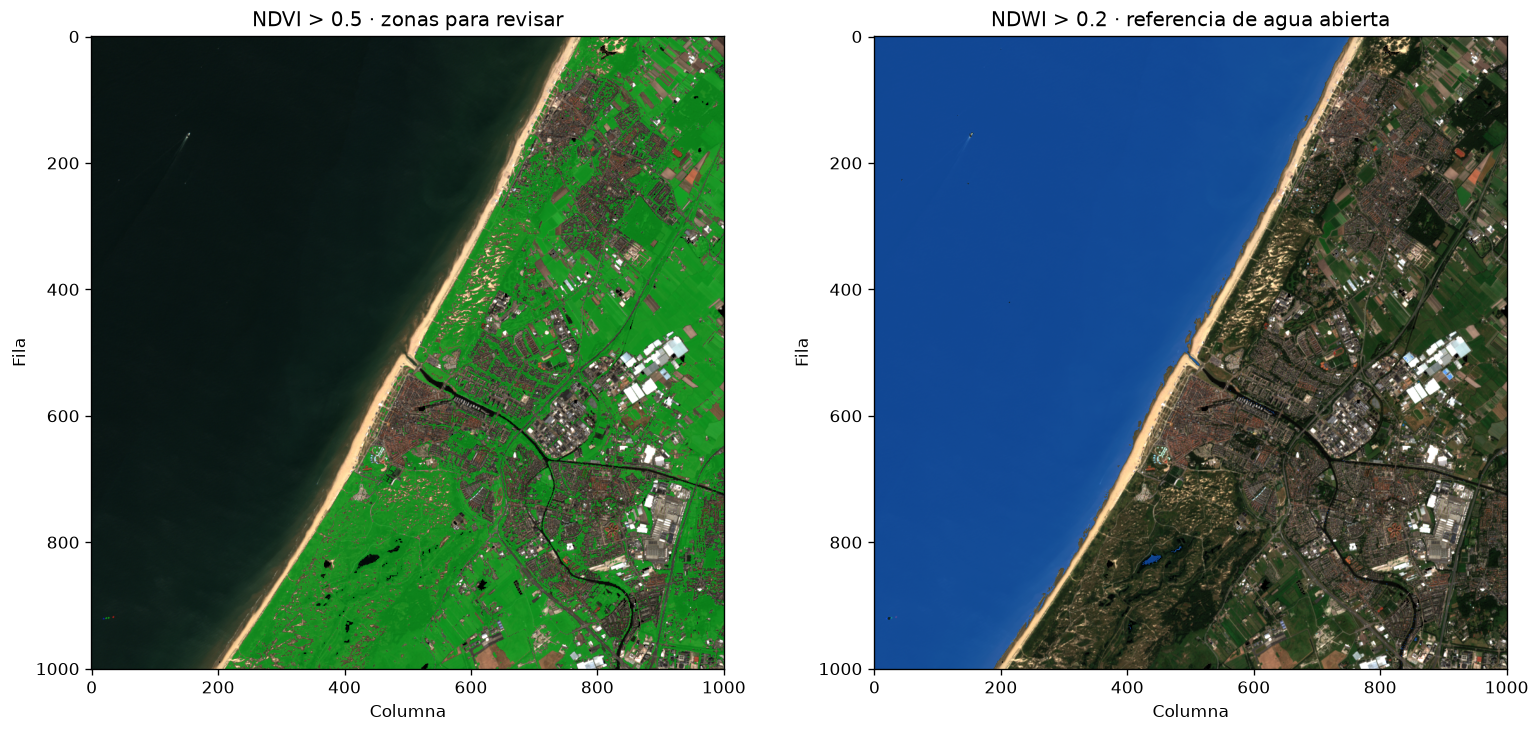

In [4]:
umbral_ndvi = 0.5
cobertura_candidata = ndvi > umbral_ndvi
agua_candidata = ndwi_agua > 0.2

capa_verde = np.zeros((*ndvi.shape, 4))
capa_verde[cobertura_candidata] = (0.05, 0.85, 0.15, 0.55)
capa_azul = np.zeros((*ndwi_agua.shape, 4))
capa_azul[agua_candidata] = (0.10, 0.45, 1.00, 0.55)

fig, ejes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
ejes[0].imshow(rgb)
ejes[0].imshow(capa_verde)
ejes[0].set_title(f'NDVI > {umbral_ndvi} · zonas para revisar')
ejes[1].imshow(rgb)
ejes[1].imshow(capa_azul)
ejes[1].set_title('NDWI > 0.2 · referencia de agua abierta')
for ax in ejes:
    ax.set_xlabel('Columna')
    ax.set_ylabel('Fila')
plt.show()

pixeles_validos = np.isfinite(ndvi) & np.isfinite(ndwi_agua)
print(f'Pixeles marcados por NDVI: {cobertura_candidata[pixeles_validos].mean():.1%}')
print(f'Pixeles marcados por NDWI: {agua_candidata[pixeles_validos].mean():.1%}')

## Para llevar al trabajo

Al preparar un producto, registrá **qué pregunta responde, qué escena y fecha usaste, qué bandas entraron, cómo se creó la visualización o máscara y qué evidencia falta**. Una imagen RGB sin NIR no permite NDVI. Un mapa RGB estirado no reemplaza las mediciones originales. En el vuelo multiespectral de Mendoza, las bandas roja y NIR están en archivos separados: antes de combinarlas hay que revisar captura, alineación y valores comparables.

La escena Sentinel‑2B de esta práctica es de la misma región costera de la clase 2, pero otra captura y otro producto. **No compares numéricamente** los índices de 2024 con el RGB de 2020.

**Fuente:** [escena Sentinel‑2B Level‑2A, 12/08/2024](https://earth-search.aws.element84.com/v1/collections/sentinel-2-c1-l2a/items/S2B_T31UET_20240812T105014_L2A). La [ficha local](../../assets/geospatial/costa_paises_bajos_s2_20240812_fuente.md) describe la preparación de bandas y la máscara. *Contains modified Copernicus Sentinel data 2024.*